In [1]:
%%writefile ../src/explain.py
"""Lift/gains tables and SHAP helpers."""
import numpy as np
import pandas as pd


def gains_by_group(y, p, labels) -> pd.DataFrame:
    """Gains and lift when orders are ranked by group risk (a few distinct scores).

    Within a group every order has the same score, so the gains curve is a
    straight line across that group.
    """
    df = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p), "g": np.asarray(labels)})
    t = (df.groupby("g").agg(orders=("y", "size"), late=("y", "sum"), score=("p", "mean"))
           .sort_values("score", ascending=False))
    base = df["y"].mean()
    t["late_rate"] = t["late"] / t["orders"]
    t["lift"] = t["late_rate"] / base
    t["cum_orders_share"] = t["orders"].cumsum() / len(df)
    t["cum_recall"] = t["late"].cumsum() / df["y"].sum()
    return t.drop(columns="score")


def gains_by_decile(y, p, n_bins: int = 10) -> pd.DataFrame:
    """Gains and lift for a continuous score, in equal-sized bins, highest risk first."""
    df = pd.DataFrame({"y": np.asarray(y), "p": np.asarray(p)})
    df = df.sort_values("p", ascending=False, kind="mergesort").reset_index(drop=True)
    df["bin"] = (np.arange(len(df)) * n_bins // len(df)) + 1
    t = df.groupby("bin").agg(orders=("y", "size"), late=("y", "sum"))
    t["late_rate"] = t["late"] / t["orders"]
    t["lift"] = t["late_rate"] / df["y"].mean()
    t["cum_orders_share"] = t["orders"].cumsum() / len(df)
    t["cum_recall"] = t["late"].cumsum() / df["y"].sum()
    return t


def mean_abs_shap(shap_values, feature_names) -> pd.Series:
    return (pd.Series(np.abs(shap_values).mean(axis=0), index=feature_names)
              .sort_values(ascending=False))

Writing ../src/explain.py


In [2]:
import sys
sys.path.append("..")
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from src import config
from src.features import split_feature_types
from src.models import make_logreg, make_hgb
from src.evaluate import oof_predictions
from src.explain import gains_by_group, gains_by_decile, mean_abs_shap

pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)

train = pd.read_parquet(config.ROOT / "data/processed/train.parquet")
y, groups = train[config.TARGET], train["Customer Id"]
numeric, categorical = split_feature_types(train)
MODE = [config.SHIP_MODE]; all_feats = numeric + categorical
hgb_params = dict(max_depth=3, learning_rate=0.05, max_iter=200, early_stopping=False)

p_mode = oof_predictions(make_logreg(MODE, numeric), train[MODE], y, groups)
g_mode = gains_by_group(y, p_mode, train[config.SHIP_MODE]).round(4)
g_mode

,orders,late,late_rate,lift,cum_orders_share,cum_recall
g,,,,,,
First Class,21217,21217,1.0000,1.7455,0.1535,0.2680
Second Class,27144,21570,0.7947,1.3871,0.3499,0.5404
Same Day,7488,3604,0.4813,0.8401,0.4041,0.5859
Standard Class,82364,32791,0.3981,0.6949,1.0000,1.0000


In [3]:
p_hgb = oof_predictions(make_hgb(all_feats, numeric, **hgb_params), train[all_feats], y, groups)
g_hgb = gains_by_decile(y, p_hgb).round(4)
g_hgb

,orders,late,late_rate,lift,cum_orders_share,cum_recall
bin,,,,,,
1,13822,13822,1.0000,1.7455,0.1,0.1746
2,13821,12304,0.8902,1.5539,0.2,0.3299
3,13821,10981,0.7945,1.3868,0.3,0.4686
4,13822,8752,0.6332,1.1052,0.4,0.5792
5,13821,5700,0.4124,0.7199,0.5,0.6511
6,13821,5538,0.4007,0.6994,0.6,0.7211
7,13822,5477,0.3963,0.6917,0.7,0.7903
8,13821,5537,0.4006,0.6993,0.8,0.8602
9,13821,5579,0.4037,0.7046,0.9,0.9306


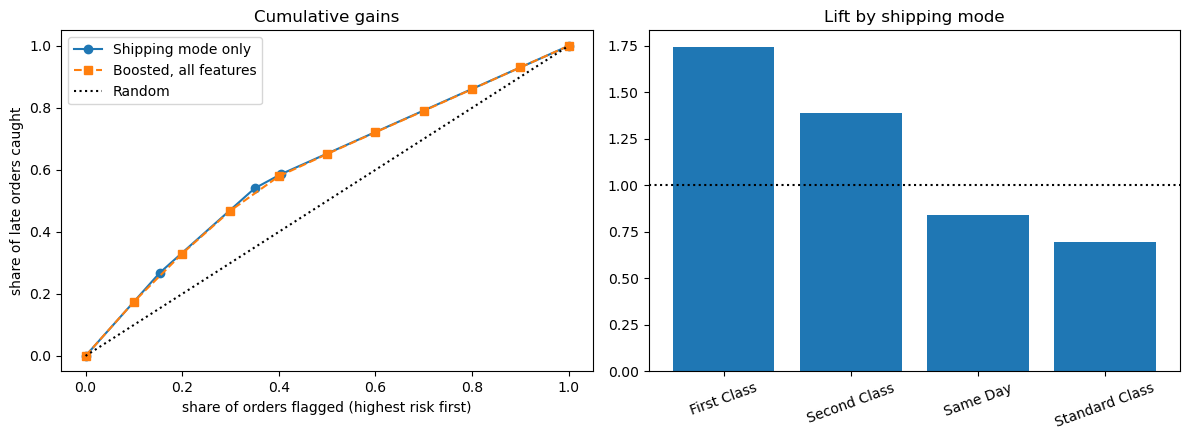

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
x0 = np.r_[0, g_mode["cum_orders_share"].values]; y0 = np.r_[0, g_mode["cum_recall"].values]
x1 = np.r_[0, g_hgb["cum_orders_share"].values];  y1 = np.r_[0, g_hgb["cum_recall"].values]
ax[0].plot(x0, y0, "o-", label="Shipping mode only")
ax[0].plot(x1, y1, "s--", label="Boosted, all features")
ax[0].plot([0, 1], [0, 1], "k:", label="Random")
ax[0].set_title("Cumulative gains")
ax[0].set_xlabel("share of orders flagged (highest risk first)")
ax[0].set_ylabel("share of late orders caught"); ax[0].legend()
ax[1].bar(g_mode.index, g_mode["lift"]); ax[1].axhline(1, color="k", ls=":")
ax[1].set_title("Lift by shipping mode"); ax[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.savefig("../reports/figures/gains_lift.png", dpi=150)
plt.show()

In [5]:
hgb = make_hgb(all_feats, numeric, **hgb_params).fit(train[all_feats], y)
prep, clf = hgb.named_steps["prep"], hgb.named_steps["clf"]

# Explain a sample of TRAIN rows. The test set stays untouched.
sample = train[all_feats].sample(2000, random_state=config.RANDOM_STATE)
Xs = pd.DataFrame(prep.transform(sample), columns=prep.get_feature_names_out(), index=sample.index)

def predict_late(X):
    return clf.predict_proba(pd.DataFrame(X, columns=Xs.columns))[:, 1]

background = Xs.sample(100, random_state=1)
to_explain = Xs.sample(300, random_state=2)
print(Xs.shape)

(2000, 18)


In [6]:
explainer = shap.Explainer(predict_late, shap.maskers.Independent(background, max_samples=100),
                           algorithm="permutation", seed=config.RANDOM_STATE)
res = explainer(to_explain.values, max_evals=2 * Xs.shape[1] + 1, silent=True)

err = np.abs(predict_late(to_explain.values) - (res.values.sum(axis=1) + res.base_values)).max()
print("Additivity max error (probability):", round(float(err), 4))   # must be near 0

imp = mean_abs_shap(res.values, Xs.columns)
print((imp / imp.sum()).round(3).head(8))

Additivity max error (probability): 0.0004
Shipping Mode          0.903
Order Country          0.040
Customer State         0.026
Product Name           0.011
Longitude              0.007
Latitude               0.006
Order Item Discount    0.004
Type                   0.002
dtype: float64


Shipping Mode
Standard Class   -0.214
Same Day         -0.133
Second Class      0.175
First Class       0.384
dtype: float64
base value: 0.614


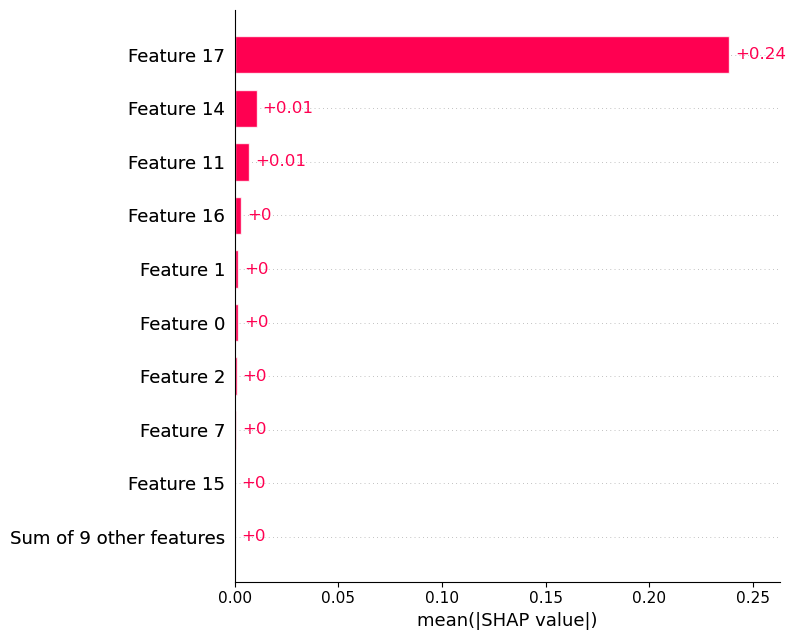

In [7]:
mi = list(Xs.columns).index(config.SHIP_MODE)
print(pd.Series(res.values[:, mi], index=to_explain.index)
      .groupby(sample.loc[to_explain.index, config.SHIP_MODE]).mean().round(3).sort_values())
print("base value:", round(float(np.mean(res.base_values)), 3))

shap.plots.bar(res, max_display=10, show=False)
plt.tight_layout(); plt.savefig("../reports/figures/shap_bar.png", dpi=150); plt.show()